AS vs healthy controls : FDR < 0.05 -> 1455 proteins
Samples -> female ctrl: 8 | female AS: 21 | male ctrl: 9 | male AS: 20 
Sex-dependent AS response: FDR < 0.05 -> 0 proteins
AS vs MR : FDR < 0.05 -> 907 proteins
Done.



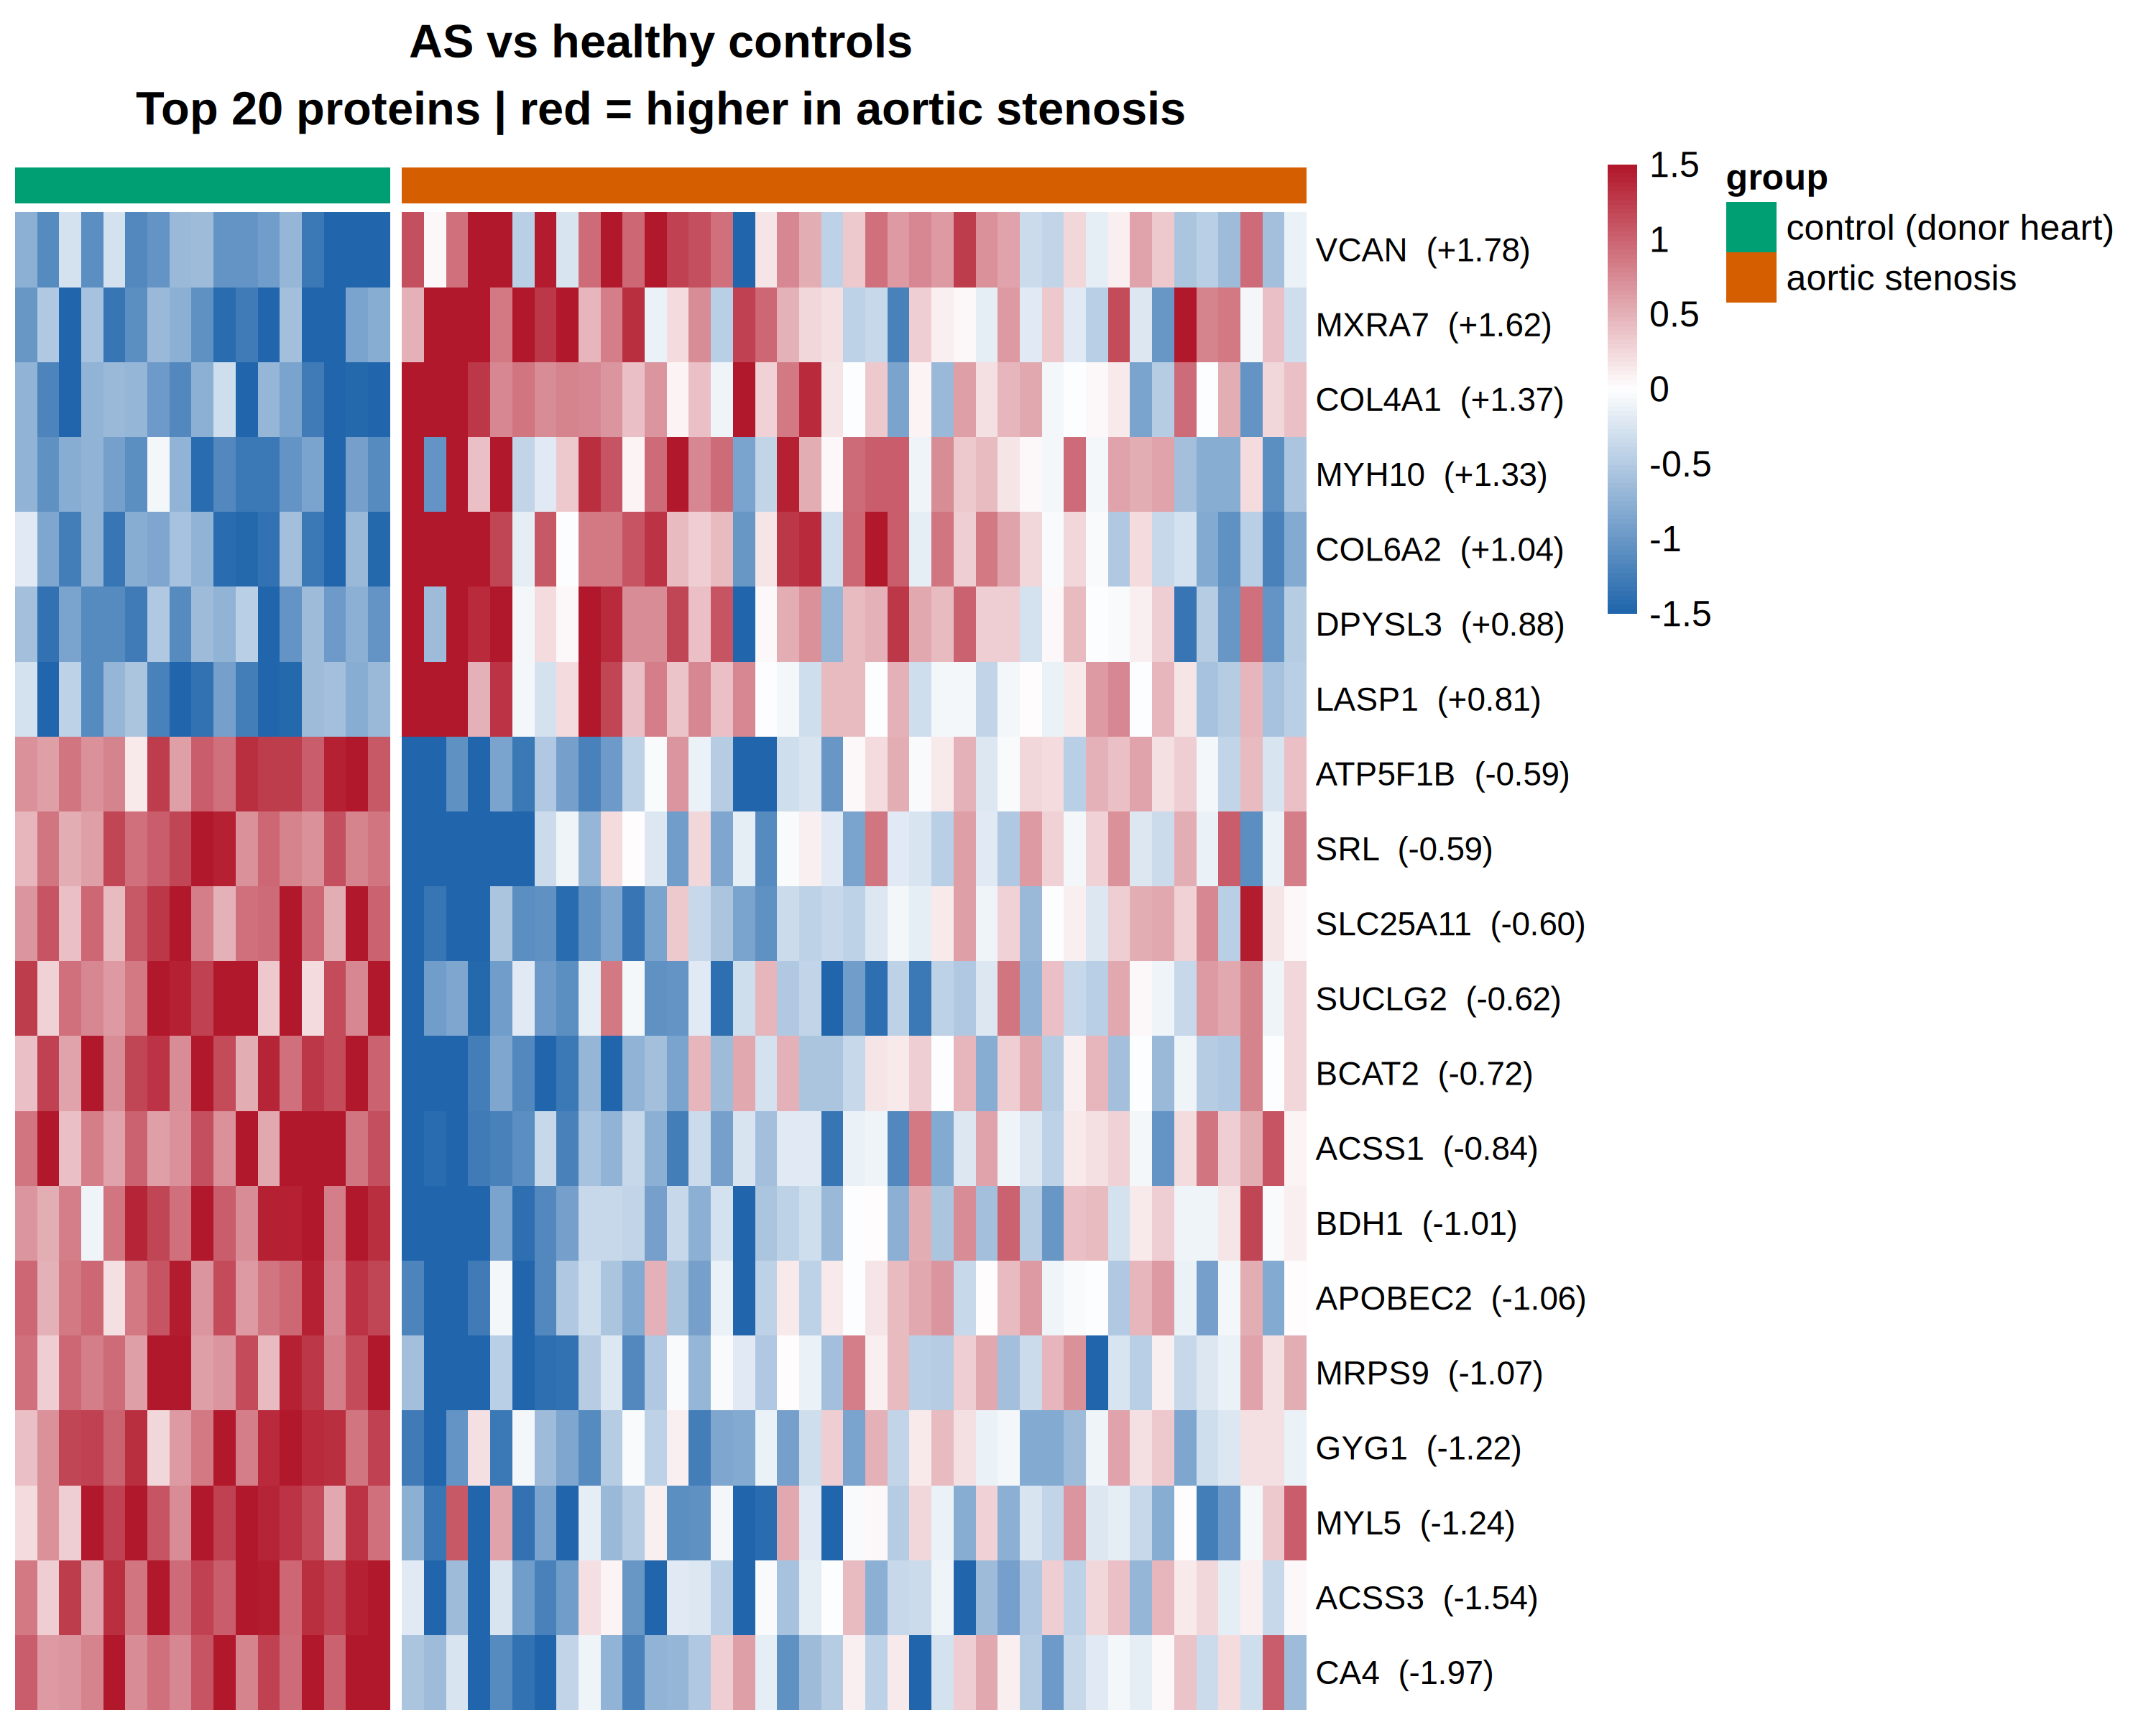

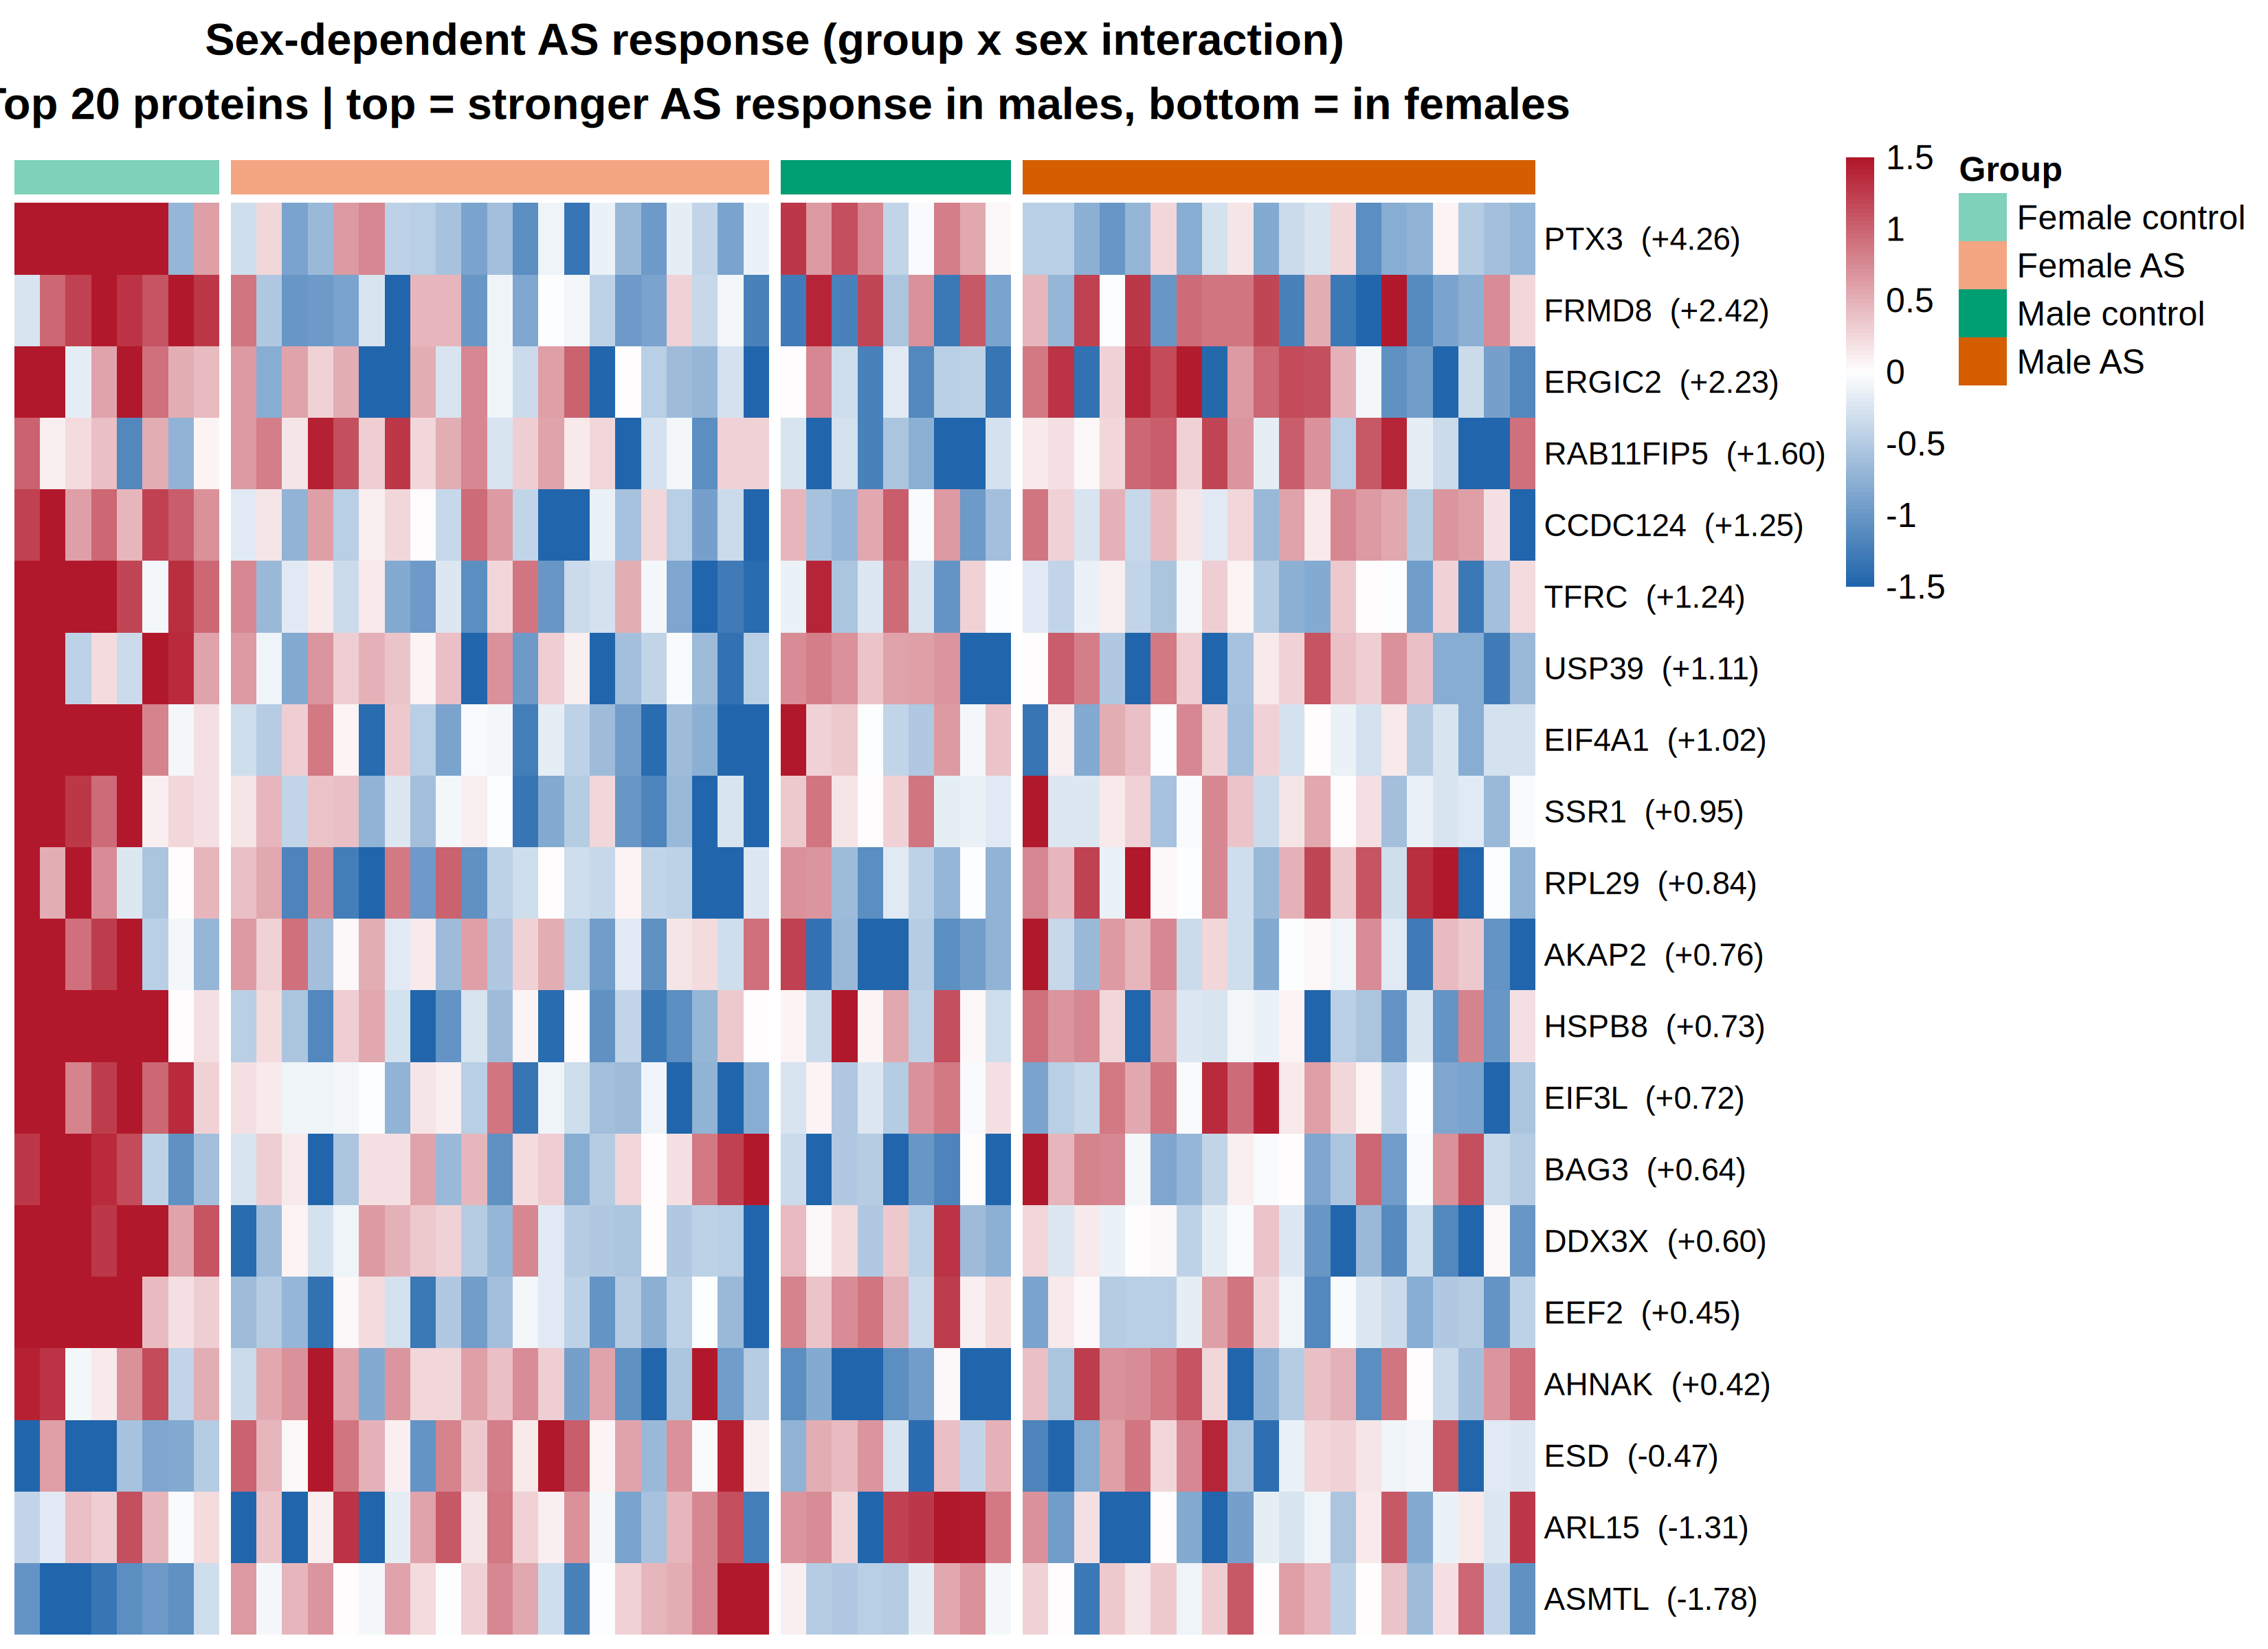

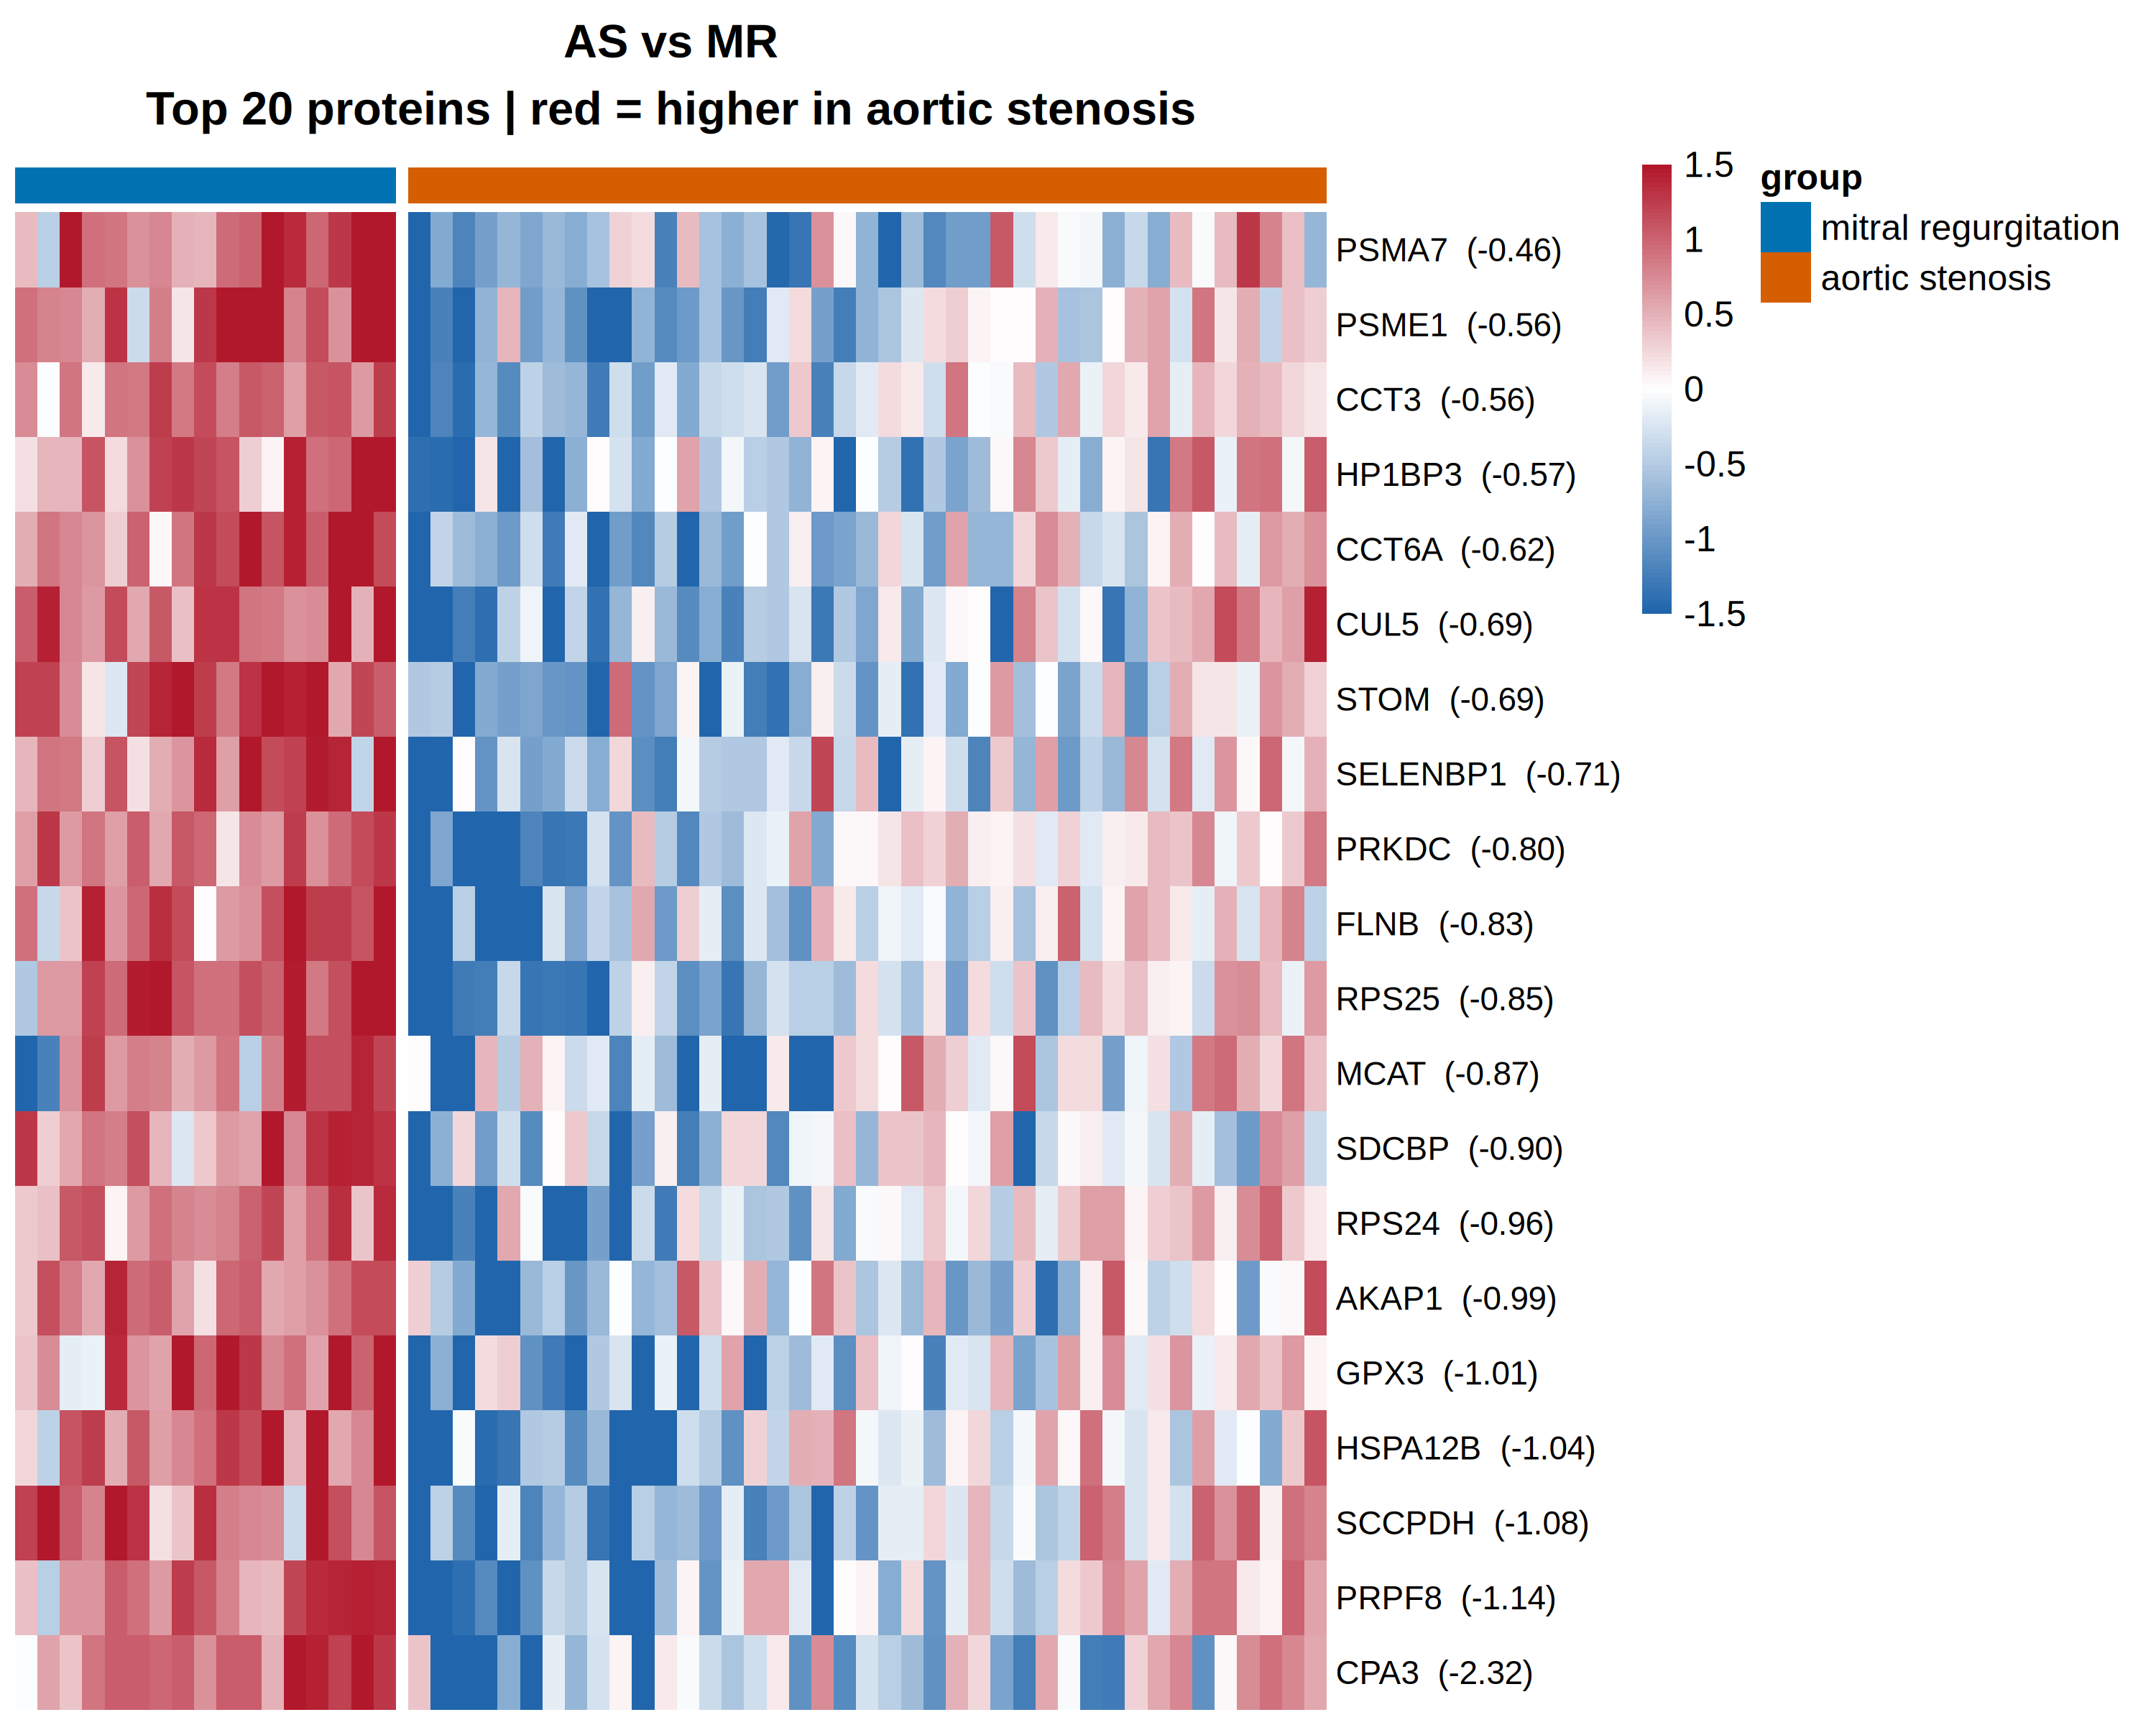

In [21]:
# ============================================================
# 3 focused heatmaps:
#   1) AS vs healthy controls
#   2) Sex-dependent AS response (group x sex interaction)
#   3) AS vs MR
# ============================================================
import subprocess
from pathlib import Path
from IPython.display import Image, display

r_code = r'''
suppressPackageStartupMessages(library(pheatmap))

in_dir  <- "/content/pheatmap_input"
out_dir <- "/content"

# ---------- Import ----------
expr_norm <- as.matrix(read.csv(file.path(in_dir, "expression_log2_normalized.csv"),
                                row.names = 1, check.names = FALSE))
expr_imp  <- as.matrix(read.csv(file.path(in_dir, "expression_log2_imputed.csv"),
                                row.names = 1, check.names = FALSE))
storage.mode(expr_norm) <- "numeric"; storage.mode(expr_imp) <- "numeric"

sample_annot  <- read.csv(file.path(in_dir, "sample_annotation.csv"),
                          row.names = 1, check.names = FALSE)
protein_annot <- read.csv(file.path(in_dir, "protein_annotation.csv"), check.names = FALSE)
rownames(protein_annot) <- protein_annot$protein_group_id

sample_annot <- sample_annot[colnames(expr_norm), c("group", "sex"), drop = FALSE]
expr_imp <- expr_imp[, colnames(expr_norm)]

CTRL <- "control (donor heart)"; AS <- "aortic stenosis"; MR <- "mitral regurgitation"

# ---------- Settings ----------
top_n <- 20
lim   <- 1.5
heat_cols <- colorRampPalette(c("#2166AC", "white", "#B2182B"))(100)

col_group <- c("control (donor heart)" = "#009E73",
               "aortic stenosis"       = "#D55E00",
               "mitral regurgitation"  = "#0072B2")

gene_col <- intersect(c("gene_name", "gene", "Gene", "gene_names", "Gene names"),
                      colnames(protein_annot))[1]
get_labels <- function(ids) {
    if (is.na(gene_col)) return(ids)
    g <- sub(";.*", "", as.character(protein_annot[ids, gene_col]))
    ifelse(is.na(g) | g == "", ids, g)
}
ids <- function(var, val) rownames(sample_annot)[sample_annot[[var]] == val]

zscore <- function(m) { z <- t(scale(t(m))); z[is.nan(z)] <- 0; z }
clip   <- function(z) { z[z > lim] <- lim; z[z < -lim] <- -lim; z }

# ============================================================
# A) Two-group comparison (a minus b)
# ============================================================
two_group_heatmap <- function(g_a, g_b, tag, title) {
    s_a <- ids("group", g_a); s_b <- ids("group", g_b)

    res <- t(apply(expr_norm, 1, function(x) {
        a <- x[s_a]; a <- a[!is.na(a)]
        b <- x[s_b]; b <- b[!is.na(b)]
        if (length(a) < 3 || length(b) < 3) return(c(log2FC = NA_real_, p = NA_real_))
        p <- tryCatch(t.test(a, b)$p.value, error = function(e) NA_real_)
        c(log2FC = mean(a) - mean(b), p = p)
    }))
    res <- as.data.frame(res)
    res$FDR <- p.adjust(res$p, method = "BH")
    res$protein <- rownames(res)
    write.csv(res, file.path(out_dir, paste0("DE_", tag, ".csv")), row.names = FALSE)
    cat(title, ": FDR < 0.05 ->", sum(res$FDR < 0.05, na.rm = TRUE), "proteins\n")

    res <- res[!is.na(res$p), ]
    top <- res[order(res$p), ][seq_len(min(top_n, nrow(res))), ]
    top <- top[order(-top$log2FC), ]

    z_all <- zscore(expr_imp[rownames(top), c(s_b, s_a)])
    score <- colMeans(z_all * sign(top$log2FC))
    s_a <- s_a[order(score[s_a], decreasing = TRUE)]
    s_b <- s_b[order(score[s_b], decreasing = TRUE)]
    samples <- c(s_b, s_a)
    z <- clip(z_all[, samples])

    labs <- sprintf("%s  (%+.2f)", make.unique(get_labels(rownames(z))), top$log2FC)

    col_ann <- data.frame(group = factor(sample_annot[samples, "group"], levels = c(g_b, g_a)),
                          row.names = samples)

    pheatmap(z,
        color = heat_cols, breaks = seq(-lim, lim, length.out = 101),
        cluster_rows = FALSE, cluster_cols = FALSE,
        gaps_col = length(s_b),
        annotation_col = col_ann,
        annotation_colors = list(group = col_group[c(g_b, g_a)]),
        annotation_names_col = FALSE,
        labels_row = labs,
        show_colnames = FALSE, border_color = NA,
        fontsize = 12, fontsize_row = 11,
        main = paste0(title, "\nTop ", nrow(z), " proteins | red = higher in ", g_a),
        filename = file.path(out_dir, paste0("hm_", tag, ".png")),
        width = 10, height = 3 + 0.25 * nrow(z))
}

# ============================================================
# B) Sex-dependent AS response (group x sex interaction)
# ============================================================
sex_dependent_AS <- function() {
    s_fc <- intersect(ids("group", CTRL), ids("sex", "female"))
    s_fa <- intersect(ids("group", AS),   ids("sex", "female"))
    s_mc <- intersect(ids("group", CTRL), ids("sex", "male"))
    s_ma <- intersect(ids("group", AS),   ids("sex", "male"))
    cat("Samples -> female ctrl:", length(s_fc), "| female AS:", length(s_fa),
        "| male ctrl:", length(s_mc), "| male AS:", length(s_ma), "\n")
    if (min(length(s_fc), length(s_fa), length(s_mc), length(s_ma)) < 3) {
        cat("  -> a group has < 3 samples, skipped\n"); return(invisible())
    }

    samples <- c(s_fc, s_fa, s_mc, s_ma)
    d <- data.frame(
        group = factor(c(rep("ctrl", length(s_fc)), rep("AS", length(s_fa)),
                         rep("ctrl", length(s_mc)), rep("AS", length(s_ma))),
                       levels = c("ctrl", "AS")),
        sex   = factor(c(rep("female", length(s_fc) + length(s_fa)),
                         rep("male",   length(s_mc) + length(s_ma))),
                       levels = c("female", "male")))
    cell <- paste(d$group, d$sex)

    res <- t(apply(expr_norm[, samples], 1, function(y) {
        ok <- !is.na(y)
        if (any(table(factor(cell[ok], levels = unique(cell))) < 2))
            return(c(delta = NA_real_, p = NA_real_))
        fit <- tryCatch(lm(y ~ group * sex, data = d), error = function(e) NULL)
        if (is.null(fit)) return(c(delta = NA_real_, p = NA_real_))
        co <- summary(fit)$coefficients
        if (nrow(co) < 4) return(c(delta = NA_real_, p = NA_real_))
        m <- tapply(y[ok], cell[ok], mean)
        delta <- (m["AS male"] - m["ctrl male"]) - (m["AS female"] - m["ctrl female"])
        c(delta = unname(delta), p = co[4, 4])
    }))
    res <- as.data.frame(res)
    res$FDR <- p.adjust(res$p, method = "BH")
    res$protein <- rownames(res)
    write.csv(res, file.path(out_dir, "DE_sex_dependent_AS_interaction.csv"), row.names = FALSE)
    cat("Sex-dependent AS response: FDR < 0.05 ->", sum(res$FDR < 0.05, na.rm = TRUE), "proteins\n")

    res <- res[!is.na(res$p), ]
    top <- res[order(res$p), ][seq_len(min(top_n, nrow(res))), ]
    top <- top[order(-top$delta), ]

    z_all <- zscore(expr_imp[rownames(top), samples])

    # Order samples inside each block by a signature score
    score <- colMeans(z_all * sign(top$delta))
    ord <- function(s) s[order(score[s], decreasing = TRUE)]
    blocks <- list(ord(s_fc), ord(s_fa), ord(s_mc), ord(s_ma))
    samples <- unlist(blocks)
    z <- clip(z_all[, samples])

    lv <- c("Female control", "Female AS", "Male control", "Male AS")
    col_ann <- data.frame(
        Group = factor(rep(lv, sapply(blocks, length)), levels = lv),
        row.names = samples)
    ann_col <- list(Group = c("Female control" = "#7FD1B9", "Female AS" = "#F4A582",
                              "Male control"   = "#009E73", "Male AS"   = "#D55E00"))

    labs <- sprintf("%s  (%+.2f)", make.unique(get_labels(rownames(z))), top$delta)

    pheatmap(z,
        color = heat_cols, breaks = seq(-lim, lim, length.out = 101),
        cluster_rows = FALSE, cluster_cols = FALSE,
        gaps_col = cumsum(sapply(blocks, length))[1:3],
        annotation_col = col_ann, annotation_colors = ann_col,
        annotation_names_col = FALSE,
        labels_row = labs,
        show_colnames = FALSE, border_color = NA,
        fontsize = 12, fontsize_row = 11,
        main = paste0("Sex-dependent AS response (group x sex interaction)",
                      "\nTop ", nrow(z), " proteins | top = stronger AS response in males, bottom = in females"),
        filename = file.path(out_dir, "hm_sex_dependent_AS.png"),
        width = 11, height = 3 + 0.25 * nrow(z))
}

# ---------- Run ----------
two_group_heatmap(AS, CTRL, "AS_vs_control", "AS vs healthy controls")
sex_dependent_AS()
two_group_heatmap(AS, MR,   "AS_vs_MR",      "AS vs MR")
cat("Done.\n")
'''

Path("/content/three_heatmaps.R").write_text(r_code)

proc = subprocess.run(["Rscript", "/content/three_heatmaps.R"],
                      capture_output=True, text=True)
print(proc.stdout)
if proc.returncode != 0:
    print("R ERROR:\n", proc.stderr)

for name in ["hm_AS_vs_control", "hm_sex_dependent_AS", "hm_AS_vs_MR"]:
    p = Path(f"/content/{name}.png")
    if p.exists():
        display(Image(str(p)))

## 1. AS vs Control
which proteins are upregulated or downregulated in the left ventricular myocardium of patients with aortic stenosis compared with healthy individuals

## 2. Sex dependent AS response
do males and females exhibit different protein remodeling patterns in response to aortic stenosis

## 3. AS vs MR
are the proteomic changes associated with pressure overload different from those associated with volume overload

